In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

MODEL_PATH = PROJECT_ROOT/"models"/"face_landmarker.task"
print("model path  : " , MODEL_PATH)
print("model_exists : " , MODEL_PATH.exists)

model path  :  E:\focusai\FocusAI\models\face_landmarker.task
model_exists :  <bound method Path.exists of WindowsPath('E:/focusai/FocusAI/models/face_landmarker.task')>


In [5]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision



base_options = python.BaseOptions(
    model_asset_path= MODEL_PATH
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1
)

detector = vision.FaceLandmarker.create_from_options(options)

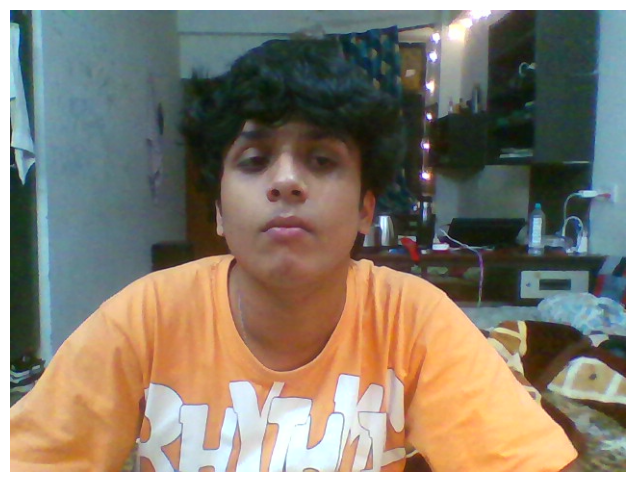

In [11]:
cap = cv2.VideoCapture(0)

ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Camera capture failed")

h, w, _ = frame.shape

rgb_frame = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 6))
plt.imshow(rgb_frame)
plt.axis("off");

In [12]:
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_frame
)

results = detector.detect(mp_image)

if not results.face_landmarks:
    raise RuntimeError("No face detected")

landmarks = results.face_landmarks[0]

print("Total landmarks:", len(landmarks))

Total landmarks: 478


In [14]:
LEFT_IRIS = 468
RIGHT_IRIS = 473

In [15]:
def get_point(landmarks, index, width, height):

    x = int(landmarks[index].x * width)
    y = int(landmarks[index].y * height)

    return np.array([x, y])


left_iris = get_point(
    landmarks, LEFT_IRIS, w, h
)

right_iris = get_point(
    landmarks, RIGHT_IRIS, w, h
)

print("Left iris:", left_iris)
print("Right iris:", right_iris)

Left iris: [256 157]
Right iris: [324 157]


In [16]:
def get_point(landmarks, index, width, height):

    x = int(landmarks[index].x * width)
    y = int(landmarks[index].y * height)

    return np.array([x, y])


left_iris = get_point(
    landmarks, LEFT_IRIS, w, h
)

right_iris = get_point(
    landmarks, RIGHT_IRIS, w, h
)

print("Left iris:", left_iris)
print("Right iris:", right_iris)

Left iris: [256 157]
Right iris: [324 157]


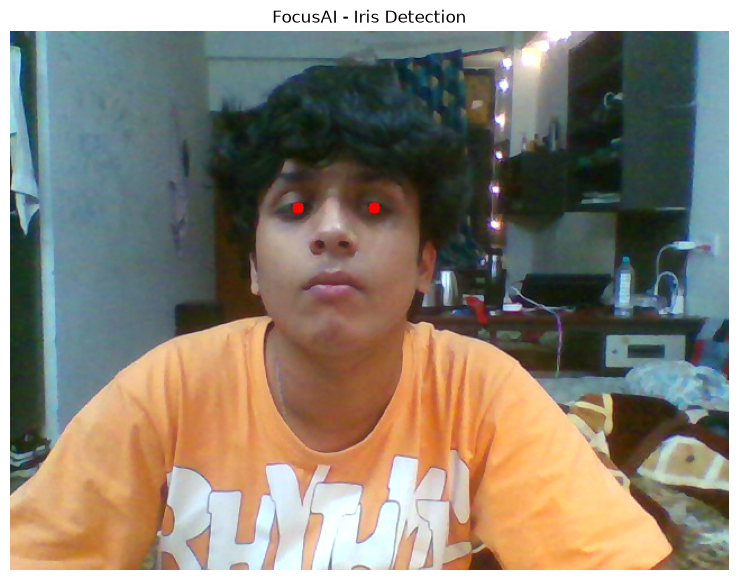

In [17]:
annotated = rgb_frame.copy()

for point in [left_iris, right_iris]:

    cv2.circle(
        annotated,
        tuple(point),
        5,
        (255, 0, 0),
        -1
    )

plt.figure(figsize=(10, 7))
plt.imshow(annotated)
plt.title("FocusAI - Iris Detection")
plt.axis("off");

In [20]:
%cd E:/focusai/FocusAI
!dir
!rmdir /s /q notebooks\.git

E:\focusai\FocusAI
 Volume in drive E is New Volume
 Volume Serial Number is CC39-3C59

 Directory of E:\focusai\FocusAI

11/14/2026  05:12 PM    <DIR>          .
11/13/2026  11:30 PM    <DIR>          ..
11/13/2026  11:30 PM    <DIR>          data
11/14/2026  02:54 PM    <DIR>          models
11/14/2026  06:04 PM    <DIR>          notebooks
11/13/2026  11:30 PM    <DIR>          outputs
11/13/2026  11:30 PM                85 README.md
               1 File(s)             85 bytes
               6 Dir(s)  27,166,691,328 bytes free


In [21]:
!git init
!git branch -M main
!git add .
!git commit -m "Initial2 commit :FocusAI project"
!git remote add origin https://github.com/triyanjha04-dev/Focus-ai.git

Reinitialized existing Git repository in E:/focusai/FocusAI/.git/


[main 86af286] Initial2 commit :FocusAI project
 7 files changed, 1358 insertions(+), 503 deletions(-)
 rename notebooks/.ipynb_checkpoints/{04_Head_Pose_Estimation-checkpoint.ipynb => 04_Real_Time_Eye_Tracking-checkpoint.ipynb} (100%)
 rename notebooks/{05_Gaze_Estimation.ipynb => .ipynb_checkpoints/05_Head_Pose_Estimation-checkpoint.ipynb} (100%)
 rename notebooks/{06_Attention_Feature_Extraction.ipynb => .ipynb_checkpoints/06_Gaze_Estimation-checkpoint.ipynb} (100%)
 delete mode 100644 notebooks/04_Head_Pose_Estimation.ipynb
 create mode 100644 notebooks/04_Real_Time_Eye_Tracking.ipynb
 create mode 100644 notebooks/05_Head_Pose_Estimation.ipynb
 create mode 100644 notebooks/06_Gaze_Estimation.ipynb


error: remote origin already exists.


In [22]:
!git push -u origin main

branch 'main' set up to track 'origin/main'.


To https://github.com/triyanjha04-dev/Focus-ai.git
   235c15e..86af286  main -> main


In [37]:
import os 
print("current directory : " , os.getcwd())
print("files" , os.listdir())

current directory :  E:\focusai\FocusAI
files ['.git', 'data', 'models', 'notebooks', 'outputs', 'README.md']


In [38]:
print(os.path.exists("../models"))
print(os.path.exists("../models/face_landmarker.task"))

False
False
